# Tome S4, Chapter 1: A Map of the Series (Python companion)

Exercises first, solutions at the end. Everything in this book is generated from one file, `series.json`, which lists every tome, chapter,
numbered result and reference between tomes. Here we load it, turn it into a graph and ask the questions a map should answer:
which tome leans on which (Figure 1.1), what you must read before a given tome, which results hold the series together, and whose names
appear most often in the index of Chapter 10. We use `networkx`, `numpy` and `matplotlib`.

*Before each solution, guess the answer from Chapter 1.*

In [1]:
import json, re, unicodedata
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

for cand in ["../../tomeS4-companion/data/series.json", "tomeS4-companion/data/series.json", "series.json"]:
    if Path(cand).exists():
        D = json.load(open(cand)); break
tomes, cites = D["tomes"], D["citations"]
order = [t["num"] for t in D["plan"]]
print(len(tomes), "tomes written,", len(cites), "references between tomes")

21 tomes written, 2225 references between tomes


## Exercises

**P1.1 (★) The citation graph.** Build the directed graph whose vertices are the tomes and with an edge $A\to B$ of weight $w$ when tome $A$ refers
$w$ times to results of tome $B$. Which tome is cited by the most other tomes? Which tome cites the most other tomes? Compare with
Figure 1.1.

**P1.2 (★★) Backwards references.** A reference from a tome to a tome with a smaller number in the same part is a step back; one to a later tome is
a promise. Is the graph acyclic? List the pairs of tomes that cite each other, and explain why they can.

**P1.3 (★★) What to read first.** For Tome 13, find all the tomes it leans on directly or indirectly (its ancestors in the graph). Then
produce a reading order: a topological order of those ancestors, if there is one.

**P1.4 (★) Pillars.** Leaving aside references to whole chapters, which ten results are cited by the largest number of different tomes? Which by the largest number of references?

**P1.5 (★) Names.** Split the names of named results into person names (words with a capital letter) and count them. Who appears in the most
results? In the most tomes? How many results carry Dirichlet's name, as the think box of Chapter 2 asks?

**P1.6 (★★) PageRank of the series.** Compute the PageRank of the tomes in the citation graph (a random reader who follows references).
Which tomes come out on top, and why does the ranking differ from the raw count of P1.1?

## Solutions

### P1.1
Each reference in the data carries the citing tome (`from`), the cited tome (`to`) and the result number.

28 vertices, 127 edges
cited by most tomes: ['1', '2', '4', '0', '3'] [17, 15, 14, 13, 13]
cites most tomes:   ['S1', '9', '8', 'S3', 'C1'] [12, 10, 9, 9, 8]


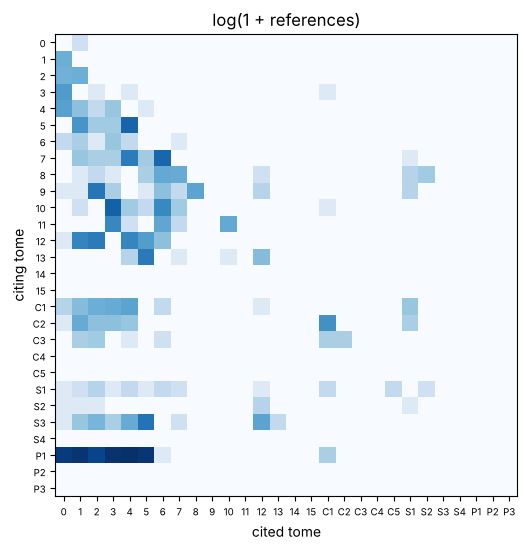

In [2]:
G = nx.DiGraph()
G.add_nodes_from(order)
for c in cites:
    if c["from"] == c["to"]: continue
    w = G[c["from"]][c["to"]]["weight"] + 1 if G.has_edge(c["from"], c["to"]) else 1
    G.add_edge(c["from"], c["to"], weight=w)
print(G.number_of_nodes(), "vertices,", G.number_of_edges(), "edges")
print("cited by most tomes:", sorted(G.nodes, key=lambda v: -G.in_degree(v))[:5],
      [G.in_degree(v) for v in sorted(G.nodes, key=lambda v: -G.in_degree(v))[:5]])
print("cites most tomes:  ", sorted(G.nodes, key=lambda v: -G.out_degree(v))[:5],
      [G.out_degree(v) for v in sorted(G.nodes, key=lambda v: -G.out_degree(v))[:5]])
M = np.zeros((len(order), len(order)))
idx = {t: i for i, t in enumerate(order)}
for a, b, d in G.edges(data=True): M[idx[a], idx[b]] = d["weight"]
plt.figure(figsize=(6, 6)); plt.imshow(np.log1p(M), cmap="Blues")
plt.xticks(range(len(order)), order, fontsize=7); plt.yticks(range(len(order)), order, fontsize=7)
plt.xlabel("cited tome"); plt.ylabel("citing tome"); plt.title("log(1 + references)"); plt.show()

The picture should look like Figure 1.1: almost everything sits on one side of the diagonal, because a tome mostly uses what came
before it.

### P1.2
`nx.simple_cycles` lists the cycles; a pair of tomes citing each other is a cycle of length 2.

In [3]:
print("acyclic:", nx.is_directed_acyclic_graph(G))
mutual = sorted({tuple(sorted((a, b), key=order.index)) for a, b in G.edges if G.has_edge(b, a)}, key=lambda p: [order.index(x) for x in p])
for a, b in mutual:
    print(f"Tome {a} -> Tome {b}: {G[a][b]['weight']:3d}   Tome {b} -> Tome {a}: {G[b][a]['weight']:3d}")
fwd = [c for c in cites if c["from"] != c["to"] and order.index(c["to"]) > order.index(c["from"])]
print(len(fwd), "references point to a later tome")

acyclic: False
Tome 0 -> Tome 1:   2   Tome 1 -> Tome 0:  13
Tome 3 -> Tome 4:   1   Tome 4 -> Tome 3:   7
Tome 3 -> Tome C1:   1   Tome C1 -> Tome 3:  14
Tome 4 -> Tome 5:   1   Tome 5 -> Tome 4:  68
Tome 6 -> Tome 7:   1   Tome 7 -> Tome 6:  66
Tome 7 -> Tome S1:   1   Tome S1 -> Tome 7:   2
Tome C1 -> Tome S1:   7   Tome S1 -> Tome C1:   3
Tome S1 -> Tome S2:   2   Tome S2 -> Tome S1:   1
42 references point to a later tome


Mutual references are not circular reasoning: a later tome proves a result the earlier one only announced (a promise), or an earlier tome
looks ahead in a remark or an exercise. What matters is that no *proof* depends on itself, which the books check by hand.

### P1.3
If the graph has cycles we cannot topologically sort it directly; we first contract its strongly connected components.

In [4]:
anc = nx.descendants(G, "13")    # edges point from the citing tome to the cited one
print("Tome 13 leans on:", sorted(anc, key=order.index))
H = G.subgraph(anc | {"13"})
C = nx.condensation(H)
reading = []
for comp in reversed(list(nx.topological_sort(C))):
    reading.append(sorted(C.nodes[comp]["members"], key=order.index))
print("a reading order (tomes in one bracket cite each other):")
print(" -> ".join("[" + ", ".join(r) + "]" if len(r) > 1 else r[0] for r in reading))

Tome 13 leans on: ['0', '1', '2', '3', '4', '5', '6', '7', '10', '12', 'C1', 'C5', 'S1', 'S2']
a reading order (tomes in one bracket cite each other):
[0, 1] -> C5 -> 2 -> [3, 4, 5, 6, 7, 12, C1, S1, S2] -> 10 -> 13


### P1.4

In [5]:
names = {}
for t, T in tomes.items():
    for ch in T["chapters"]:
        for r in ch["results"]:
            names[(t, r["kind"], r["num"])] = r.get("name")
kindmap = {"Theorem": "theorem", "Proposition": "proposition", "Lemma": "lemma", "Corollary": "corollary",
           "Definition": "definition", "Example": "example", "Exercise": "exercise"}
by_tomes, by_refs = defaultdict(set), Counter()
for c in cites:
    if c["from"] == c["to"] or c["word"] == "Chapter": continue
    key = (c["to"], c["word"], c["num"])
    by_tomes[key].add(c["from"]); by_refs[key] += 1
def label(k):
    n = names.get((k[0], kindmap.get(k[1], k[1].lower()), k[2]))
    return f"Tome {k[0]}, {k[1]} {k[2]}" + (f" ({n})" if n else "")
print("by number of citing tomes:")
for k in sorted(by_tomes, key=lambda k: (-len(by_tomes[k]), -by_refs[k]))[:10]:
    print(f"  {len(by_tomes[k]):2d} tomes  {label(k)}")
print("by number of references:")
for k, n in by_refs.most_common(10):
    print(f"  {n:2d} refs   {label(k)}")

by number of citing tomes:
   5 tomes  Tome 4, Theorem 10.3 (Euler product)
   4 tomes  Tome 5, Theorem 3.5
   4 tomes  Tome 5, Theorem 1.5 (Mertens, 1874)
   4 tomes  Tome 4, Proposition 10.6
   4 tomes  Tome 2, Theorem 11.14 (Fourier analysis on a finite abelian group)
   4 tomes  Tome 2, Theorem 9.6 (Galois, Moore)
   4 tomes  Tome 5, Theorem 5.2 (Hadamard, de la Vallée Poussin, 1896)
   3 tomes  Tome 4, Theorem 9.15 (limits and integrals)
   3 tomes  Tome 5, Theorem 5.5 (the prime number theorem)
   3 tomes  Tome 1, Theorem 7.3
by number of references:
  20 refs   Tome 4, Theorem 9.15 (limits and integrals)
  18 refs   Tome 5, Theorem 5.5 (the prime number theorem)
  17 refs   Tome 5, Theorem 5.8 (the prime number theorem for arithmetic progressions)
  15 refs   Tome 4, Theorem 10.3 (Euler product)
  12 refs   Tome 5, Theorem 3.5
  11 refs   Tome 4, Corollary 11.6 (harmonic numbers)
  11 refs   Tome 5, Theorem 1.5 (Mertens, 1874)
  10 refs   Tome 5, Theorem 1.6 (Mertens, 1874)
   9

### P1.5
A crude rule: a person name is a capitalised word that is not the first word of a sentence-like name such as *Fundamental*. We strip
TeX accents first. The rule makes mistakes (try to find some), which is why the index in the book is sorted by whole names.

In [6]:
def clean(s):
    s = re.sub(r"\\(?:[\"'`^~=.]|[Hvcuk](?=[\s{]))\s*\{?(\w)\}?", r"\1", s)
    s = unicodedata.normalize("NFKD", s.replace("Ł", "L"))
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    s = re.sub(r"\\[a-zA-Z]+", " ", s)
    return re.sub(r"[${}~]", " ", s)
skip = {"The", "A", "An", "Fundamental", "Fourier", "Q", "Z", "R", "C", "F", "L", "I", "II", "III"}
skip.discard("Fourier")    # Fourier is a person
people, ptomes = Counter(), defaultdict(set)
for t, T in tomes.items():
    for ch in T["chapters"]:
        for r in ch["results"]:
            if r["kind"] in ("exercise", "example") or not r.get("name"): continue
            words = set(re.findall(r"\b[A-Z][a-z]+(?:-[A-Z][a-z]+)?\b", clean(r["name"]).replace("'s", "")))
            for w in words - skip:
                for part in w.split("-"):
                    people[part] += 1; ptomes[part].add(t)
for p, n in people.most_common(15):
    print(f"{p:12s} {n:3d} results in {len(ptomes[p]):2d} tomes")
print("Dirichlet:", people["Dirichlet"], "results in", len(ptomes["Dirichlet"]), "tomes")

Gauss         29 results in  9 tomes
Euler         28 results in  7 tomes
Cauchy        19 results in 11 tomes
Dirichlet     19 results in  8 tomes
Erdos         15 results in  8 tomes
Levy          15 results in  3 tomes
Weyl          13 results in  7 tomes
Markov        12 results in  8 tomes
Riemann       11 results in  5 tomes
Minkowski     10 results in  5 tomes
Frobenius     10 results in  6 tomes
Hilbert       10 results in  5 tomes
Poisson        9 results in  5 tomes
Riesz          9 results in  4 tomes
Kolmogorov     9 results in  4 tomes
Dirichlet: 19 results in 8 tomes


### P1.6
PageRank follows edges, so a tome ranks high when it is cited by tomes that are themselves cited. We use the weights.

In [7]:
pr = nx.pagerank(G, weight="weight")
top = sorted(pr, key=lambda v: -pr[v])[:8]
for v in top:
    print(f"Tome {v:3s} PageRank {pr[v]:.3f}   cited by {G.in_degree(v)} tomes")

Tome 0   PageRank 0.354   cited by 13 tomes
Tome 1   PageRank 0.344   cited by 17 tomes
Tome 4   PageRank 0.034   cited by 14 tomes
Tome 3   PageRank 0.032   cited by 13 tomes
Tome 2   PageRank 0.027   cited by 15 tomes
Tome 6   PageRank 0.020   cited by 10 tomes
Tome 5   PageRank 0.019   cited by 10 tomes
Tome 12  PageRank 0.013   cited by 7 tomes


Tomes 0 and 1 swallow most of the rank. They cite each other, so a random reader who reaches either of them keeps bouncing between the
two and rarely leaves: PageRank measures where such a reader spends their time, not how often a tome is cited. Remove the edges between
Tomes 0 and 1 and compute again: how does the ranking change? (The damping factor, which makes the reader jump to a random tome now and then,
is what keeps the whole rank from ending in those two books.)